## **Equipo**
- Alumno 1 : Jauregui, Lucía
- Alumno 2 : Nebbia, Maria Sofía

## **Importación de librerías**

In [52]:
from sklearn.datasets import fetch_lfw_people
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import random
import time
from collections import Counter

In [53]:
!pip install insightface
from insightface.app import FaceAnalysis
from insightface.utils import face_align

In [54]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

   ## **Elección del dataset**
Usamos **LFW (Labeled Faces in the Wild)**, un dataset público de fotos de personas conocidas obtenidas de la web. Lo cargamos con `sklearn.datasets.fetch_lfw_people`..
### Por qué elegimos LFW
Elegimos LFW por las siguientes razones:
- es un dataset de referencia en reconocimiento facial, con un protocolo oficial de pares que podemos usar para evaluar verificación.

- son fotos "in the wild" (de prensa, sin condiciones controladas), con variación de pose, iluminación, expresión y oclusiones, lo que se parece al escenario real de la app.

- permite filtrar por cantidad de imágenes: con un mínimo de 20 fotos por persona obtenemos 62 identidades y 3.023 imágenes, suficiente para entrenar una CNN desde cero.
- las identidades descartadas (con menos de 20 fotos) se reservan como personas desconocidas para evaluar el rechazo en un escenario open-set.

### Limitaciones del dataset

1. **Desbalance de clases.** Las 5 identidades más frecuentes concentran el 38% de las imágenes y George W. Bush aporta 1 de cada 5,7. *Efecto:* el modelo puede aprender mejor a las identidades más frecuentes y rendir peor con las de pocas fotos, y la accuracy global puede ocultar ese problema.

2. **Pocas identidades y pocas imágenes para una CNN desde cero.** Tras filtrar quedan 62 personas y 3.023 imágenes (mediana de 31 por persona). *Efecto:* riesgo de sobreajuste (overfitting) en el Modelo A y menor capacidad de generalizar a personas nuevas.

3. **Sesgo demográfico.** Son mayormente figuras públicas y políticos, y en nuestras muestras predominan hombres y personas de piel clara. *Efecto:* el sistema puede funcionar peor con mujeres, con personas de piel oscura o con grupos poco representados, y los resultados no se pueden extrapolar a toda la población.

4. **Calidad y resolución de las imágenes.** Son fotos chicas (125×94 px, no cuadradas) y el tamaño objetivo es 112×112, por lo que hay que agrandarlas (el 99,3% de las caras detectadas mide menos de 112 px de ancho). *Efecto:* se pierde nitidez, y el recorte o reescalado puede deformar la cara si no se hace con cuidado.

5. **Caras ya recortadas y centradas.** La cara ocupa en mediana el 96% de la imagen. *Efecto:* la etapa de detección se prueba poco con este dataset, y en la app (que recibe fotos completas) el rendimiento puede ser peor que el medido.

6. **Tipo de imagen: fotos de prensa de figuras públicas.** No hay selfies, fotos de documento ni cámaras de baja calidad, y el aspecto de las personas (maquillaje, fotos de eventos) no es el de usuarios comunes. *Efecto:* el rendimiento en el uso real de la app puede ser menor.

7. **Posibles casi-duplicados entre fotos.** Varias fotos de una misma persona pueden provenir del mismo evento y verse muy parecidas. *Efecto:* si caen en train y en test, inflan las métricas (fuga de datos). Lo controlamos con el filtro de duplicados y la partición de datos.

8. **Variación limitada.** Si bien hay variación de pose, expresión e iluminación, las fotos de cada persona se concentran en un período acotado, por lo que hay poca variación de edad. *Efecto:* el modelo puede no reconocer a la misma persona con una apariencia muy distinta.

### Filtro por cantidad de imágenes
Al cargar el dataset aplicamos `min_faces_per_person=20`, que conserva solo las identidades con al menos 20 fotos. Pasamos de 5.749 personas y 13.233 imágenes (LFW completo) a **62 personas y 3.023 imágenes**. Elegimos 20 porque una CNN entrenada desde cero necesita varias imágenes por clase, y el enunciado sugiere un mínimo de 10 a 20.

In [55]:
lfw = fetch_lfw_people(min_faces_per_person=20, color=True, resize=1.0)
print("Imágenes:", lfw.images.shape)
print("Personas:", len(lfw.target_names))

conteo = np.bincount(lfw.target)
print("Fotos por persona -> mín:", conteo.min(), "| mediana:", np.median(conteo), "| máx:", conteo.max())

Imágenes: (3023, 125, 94, 3)
Personas: 62
Fotos por persona -> mín: 20 | mediana: 31.0 | máx: 530


## **Análisis exploratorio (EDA)**

### Muestra visual del dataset
Visualizamos las primeras 10 imágenes del dataset junto con el nombre de la persona. El objetivo es comprobar que los datos se cargaron bien (imagen y etiqueta coinciden) y tener una primera impresión de cómo son las fotos: tamaño, encuadre y variación.

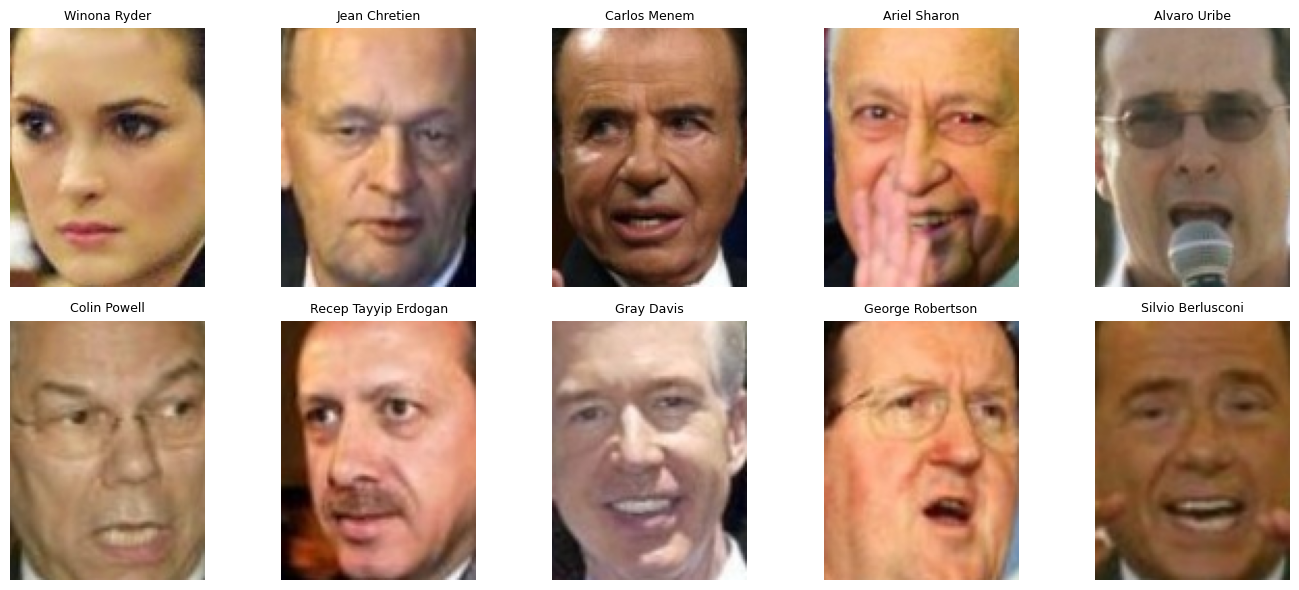

In [56]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for i, ax in enumerate(axes.flatten()):
    ax.imshow(lfw.images[i])
    ax.set_title(lfw.target_names[lfw.target[i]], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Variación dentro de una misma persona
Mostramos 10 fotos de una misma identidad (Angelina Jolie) para ver cuánto cambia su apariencia entre imágenes.

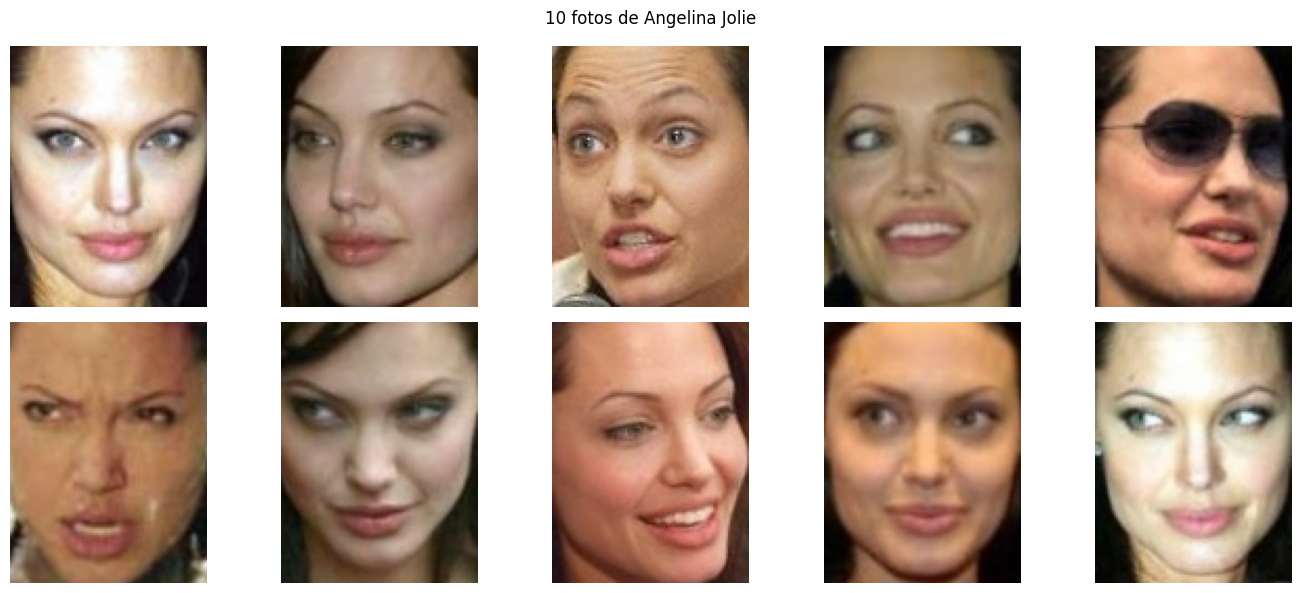

In [57]:
persona = "Angelina Jolie"
pid = np.where(lfw.target_names == persona)[0][0]
idxs = np.where(lfw.target == pid)[0][:10]

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, i in zip(axes.flatten(), idxs):
    ax.imshow(lfw.images[i])
    ax.axis("off")
plt.suptitle(f"10 fotos de {persona}")
plt.tight_layout()
plt.show()

**Observaciones:** aunque todas las imágenes son de la misma persona, hay mucha variación entre ellas:

- **Pose:** algunas son casi de frente (primera foto), pero la mayoría tiene la cabeza girada o inclinada, y en varias la mirada va hacia un costado.
- **Expresión:** hay sonrisas amplias, expresiones neutras, un gesto de enojo (fila inferior, primera foto) y una con la boca abierta, como hablando (fila superior, tercera foto).
- **Oclusiones:** en una imagen lleva anteojos de sol que tapan los ojos.
- **Iluminación y color:** algunas fotos son claras y casi sobreexpuestas, otras más oscuras, y hay diferencias de tono (más cálidas o anaranjadas frente a más frías o pálidas).
- **Encuadre:** la cara aparece más cerca de la cámara en algunas fotos que en otras.

Esta variación intra-clase es la que el modelo debe aprender a ignorar: para que el sistema funcione, dos fotos de la misma persona tienen que quedar cerca en el espacio de embeddings, aunque la pose, la expresión o la luz sean muy distintas.

In [58]:
imgs = lfw.images
brillo = imgs.mean(axis=(1, 2, 3))
contraste = imgs.std(axis=(1, 2, 3))
print("Forma del arreglo:", imgs.shape, "| tipo de dato:", imgs.dtype)
print("Imágenes con valores NaN (nulos):", np.isnan(imgs).any(axis=(1, 2, 3)).sum())
print("Imágenes con valores infinitos:", np.isinf(imgs).any(axis=(1, 2, 3)).sum())
print("Rango de valores:", imgs.min(), "a", imgs.max())
print("Imágenes totalmente uniformes (contraste = 0):", (contraste == 0).sum())
print("Imágenes casi negras (brillo < 0.05):", (brillo < 0.05).sum())
print("Imágenes casi blancas (brillo > 0.95):", (brillo > 0.95).sum())

print("\nEtiquetas:", len(lfw.target), "para", len(imgs), "imágenes | clases:", len(np.unique(lfw.target)))
print("Etiquetas fuera de rango:", ((lfw.target < 0) | (lfw.target >= len(lfw.target_names))).sum())
print("Nombres de persona duplicados:", len(lfw.target_names) - len(set(lfw.target_names)))

Forma del arreglo: (3023, 125, 94, 3) | tipo de dato: float32
Imágenes con valores NaN (nulos): 0
Imágenes con valores infinitos: 0
Rango de valores: 0.0 a 1.0
Imágenes totalmente uniformes (contraste = 0): 0
Imágenes casi negras (brillo < 0.05): 0
Imágenes casi blancas (brillo > 0.95): 0

Etiquetas: 3023 para 3023 imágenes | clases: 62
Etiquetas fuera de rango: 0
Nombres de persona duplicados: 0


**Control de integridad:** verificamos que las 3.023 imágenes se cargan correctamente: no hay valores nulos (NaN) ni infinitos, el rango de valores es [0, 1], no hay imágenes totalmente uniformes ni casi negras o blancas, y cada imagen tiene una etiqueta válida (62 clases, sin nombres duplicados). Como `scikit-learn` entrega las imágenes ya decodificadas como arreglos, no hay archivos con extensiones que auditar ni archivos que no abran.

### Cantidad de imágenes por identidad
Contamos cuántas fotos tiene cada persona del dataset filtrado (≥ 20 fotos) para estudiar el balance entre clases. Se muestran las estadísticas descriptivas, el histograma de la distribución y las 15 personas con más imágenes.

• 1 de cada 5.7 fotos es de George W Bush.
• Las 5 personas con más fotos (8% de las personas) tienen el 38% de las fotos.


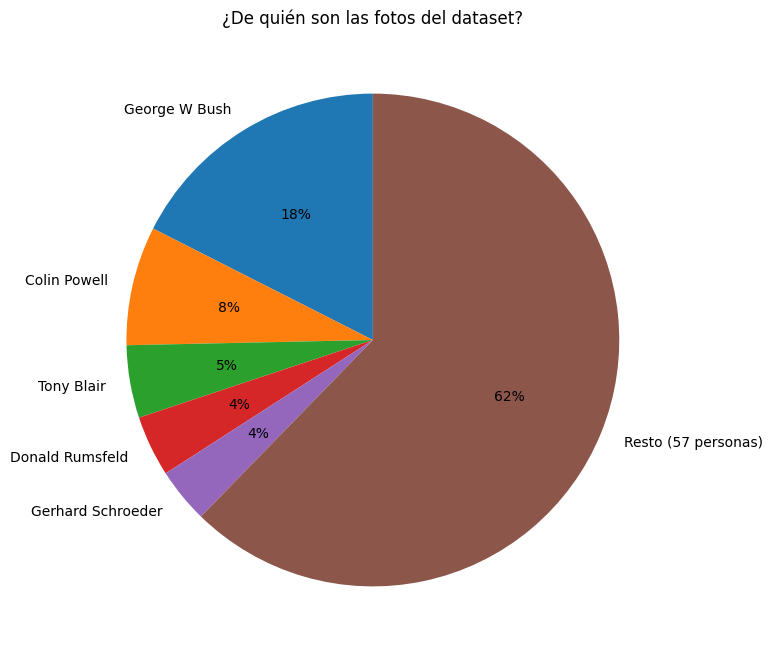

In [59]:
c = pd.Series(conteo, index=lfw.target_names).sort_values(ascending=False)
total, n = c.sum(), len(c)
top = c.index[0]

print(f"• 1 de cada {total / c.iloc[0]:.1f} fotos es de {top}.")
k5 = c.iloc[:5].sum()
print(f"• Las 5 personas con más fotos ({5 / n * 100:.0f}% de las personas) tienen el {k5 / total * 100:.0f}% de las fotos.")

partes = list(c.iloc[:5].values) + [c.iloc[5:].sum()]
nombres = list(c.index[:5]) + [f"Resto ({n - 5} personas)"]

plt.figure(figsize=(8, 8))
plt.pie(partes, labels=nombres, autopct="%1.0f%%", startangle=90)
plt.title("¿De quién son las fotos del dataset?")
plt.show()

count     62.000000
mean      48.758065
std       71.086345
min       20.000000
25%       23.000000
50%       31.000000
75%       42.000000
max      530.000000
Name: fotos, dtype: float64

Top 10 personas con más fotos:
          persona  fotos
    George W Bush    530
     Colin Powell    236
       Tony Blair    144
  Donald Rumsfeld    121
Gerhard Schroeder    109
     Ariel Sharon     77
      Hugo Chavez     71
Junichiro Koizumi     60
    Jean Chretien     55
    John Ashcroft     53


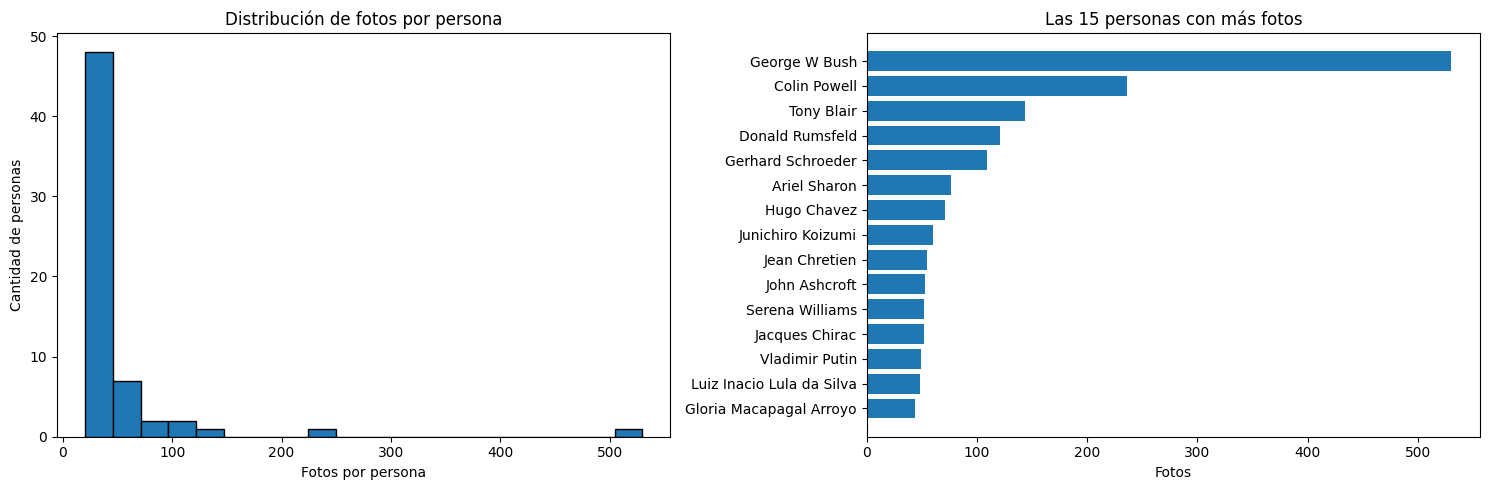

In [60]:
df = pd.DataFrame({
    "persona": lfw.target_names,
    "fotos": np.bincount(lfw.target)
}).sort_values("fotos", ascending=False)

print(df["fotos"].describe())
print("\nTop 10 personas con más fotos:")
print(df.head(10).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(df["fotos"], bins=20, edgecolor="black")
axes[0].set_xlabel("Fotos por persona")
axes[0].set_ylabel("Cantidad de personas")
axes[0].set_title("Distribución de fotos por persona")

top = df.head(15)
axes[1].barh(top["persona"], top["fotos"])
axes[1].invert_yaxis()
axes[1].set_xlabel("Fotos")
axes[1].set_title("Las 15 personas con más fotos")

plt.tight_layout()
plt.show()

El dataset tiene 62 identidades y 3.023 imágenes. La media es de 48,8 fotos por persona pero la mediana es de 31, y el desvío estándar (71,1) es mayor que la media. El 75% de las personas tiene 42 fotos o menos, mientras que George W. Bush tiene 530 y Colin Powell 236. El histograma muestra que casi todas las identidades (~48 de 62) se concentran en el rango de 20 a ~45 fotos, con unos pocos casos muy a la derecha.

**Conclusión:** el dataset está **fuertemente desbalanceado** (distribución sesgada a la derecha). Las 5 personas con más fotos (8% de las identidades) concentran el 38% de las imágenes, y Bush por sí solo aporta el 17,5%. Un modelo entrenado sin corregir esto podría favorecer a las identidades más frecuentes y rendir peor con las de pocas fotos. Para mitigarlo, en las secciones de data augmentation y de splits evaluaremos limitar el máximo de fotos por persona, aplicar augmentation sobre las identidades con menos fotos y usar muestreo ponderado, y armaremos los splits estratificados por identidad.

### Resolución, canales y formato de las imágenes
Verificamos el tamaño, la cantidad de canales y el rango de valores de las imágenes, porque el modelo necesita entradas con un formato consistente y hay que compararlo con el tamaño objetivo de cara (`FACE_SIZE` = 112×112).

In [26]:
# Resolución, canales y rango de valores
print("Tamaño de cada imagen (alto, ancho, canales):", lfw.images.shape[1:])
print("Rango de valores:", lfw.images.min(), "a", lfw.images.max())

Tamaño de cada imagen (alto, ancho, canales): (125, 94, 3)
Rango de valores: 0.0 a 1.0


**Resultados:**
- **Resolución:** todas las imágenes tienen el mismo tamaño, 125×94 píxeles (alto × ancho).
- **Canales:** 3 canales (color RGB), no hay imágenes en escala de grises.
- **Formato y rango:** valores decimales entre 0,0 y 1,0 (normalizados). Las imágenes se cargan sin errores.
- **Relación de aspecto:** 94/125 ≈ 0,75, es decir, las imágenes **no son cuadradas**.

**Conclusión y consecuencias para el pipeline:**
- El ancho (94 px) es menor que el `FACE_SIZE` objetivo (112 px), por lo que **todas las imágenes deben agrandarse**. Esto puede restar nitidez y es una limitación del dataset.
- Como no son cuadradas, al llevarlas a 112×112 hay que recortar o rellenar; si solo se estiran, la cara queda deformada. Lo resolvemos en la etapa de detección y alineación, que recorta la cara de forma consistente.
- El rango [0, 1] y el orden de canales RGB deben unificarse con el pipeline de la app (que lee con OpenCV en BGR, 0 a 255), para que la notebook y `face_service.py` procesen las imágenes igual.

### Variación de iluminación: brillo, contraste y casos difíciles
Calculamos el brillo medio y el contraste (desvío estándar de los píxeles) de cada imagen para estudiar cuánto varía la iluminación en el dataset. Después mostramos los casos extremos: las 5 imágenes más oscuras, las 5 más claras y las 5 de menor contraste.

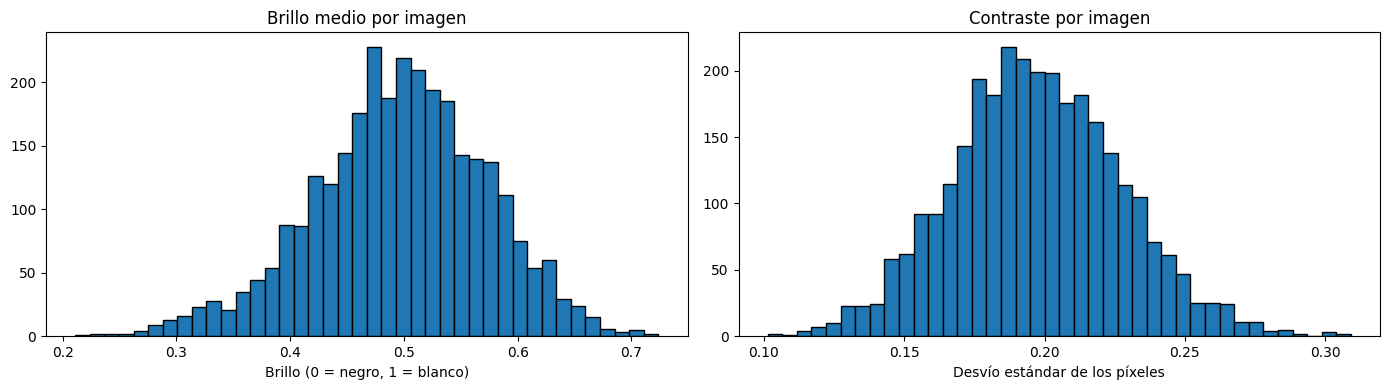

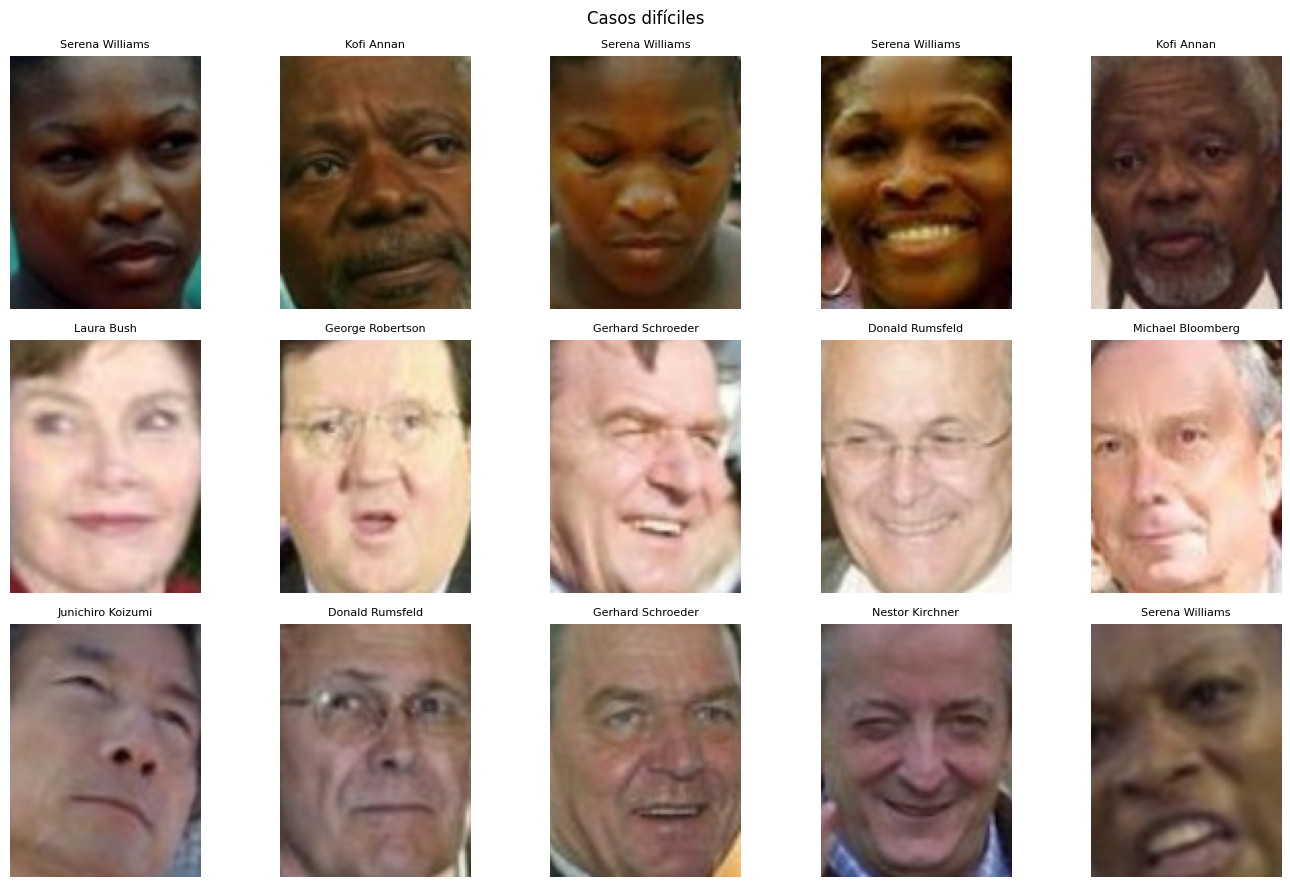

In [23]:
# Brillo y contraste de cada imagen (valores en [0, 1])
brillo = lfw.images.mean(axis=(1, 2, 3))
contraste = lfw.images.std(axis=(1, 2, 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(brillo, bins=40, edgecolor="black")
axes[0].set_title("Brillo medio por imagen")
axes[0].set_xlabel("Brillo (0 = negro, 1 = blanco)")
axes[1].hist(contraste, bins=40, edgecolor="black")
axes[1].set_title("Contraste por imagen")
axes[1].set_xlabel("Desvío estándar de los píxeles")
plt.tight_layout()
plt.show()

# Casos difíciles: las 5 más oscuras, más claras y de menor contraste
grupos = {
    "Más oscuras": np.argsort(brillo)[:5],
    "Más claras": np.argsort(brillo)[-5:],
    "Menor contraste": np.argsort(contraste)[:5],
}
fig, axes = plt.subplots(3, 5, figsize=(14, 9))
for fila, (nombre, idxs) in enumerate(grupos.items()):
    for col, i in enumerate(idxs):
        axes[fila, col].imshow(lfw.images[i])
        axes[fila, col].set_title(lfw.target_names[lfw.target[i]], fontsize=8)
        axes[fila, col].axis("off")
    axes[fila, 0].set_ylabel(nombre)
plt.suptitle("Casos difíciles")
plt.tight_layout()
plt.show()

**Resultados:** el brillo medio sigue una distribución aproximadamente normal centrada en ~0,5 (rango ~0,2 a ~0,7), y el contraste se concentra en ~0,2 (rango ~0,10 a ~0,31). No hay una proporción grande de imágenes extremas, aunque existen colas con fotos muy oscuras o muy claras.

En los casos extremos observamos variación de pose (cabezas inclinadas o mirando hacia abajo), expresión (sonrisas y gestos marcados), oclusiones (anteojos), iluminación (fotos quemadas y subexpuestas) y encuadre (distinta cercanía de la cara).

**Conclusión:** las 5 imágenes más oscuras pertenecen a personas de piel oscura (Serena Williams y Kofi Annan), por lo que el brillo medio no distingue entre mala iluminación y tono de piel. Por eso, al definir las reglas de calidad evitaremos descartar imágenes con un umbral de brillo fijo y reportaremos qué identidades afecta cada filtro, para no agravar el sesgo del dataset.

### Muestra visual: una foto por identidad
Mostramos una foto de cada una de las 62 identidades del dataset filtrado, para tener una vista general de quiénes son las personas, cómo se ven las imágenes y qué tan diversa es la muestra.

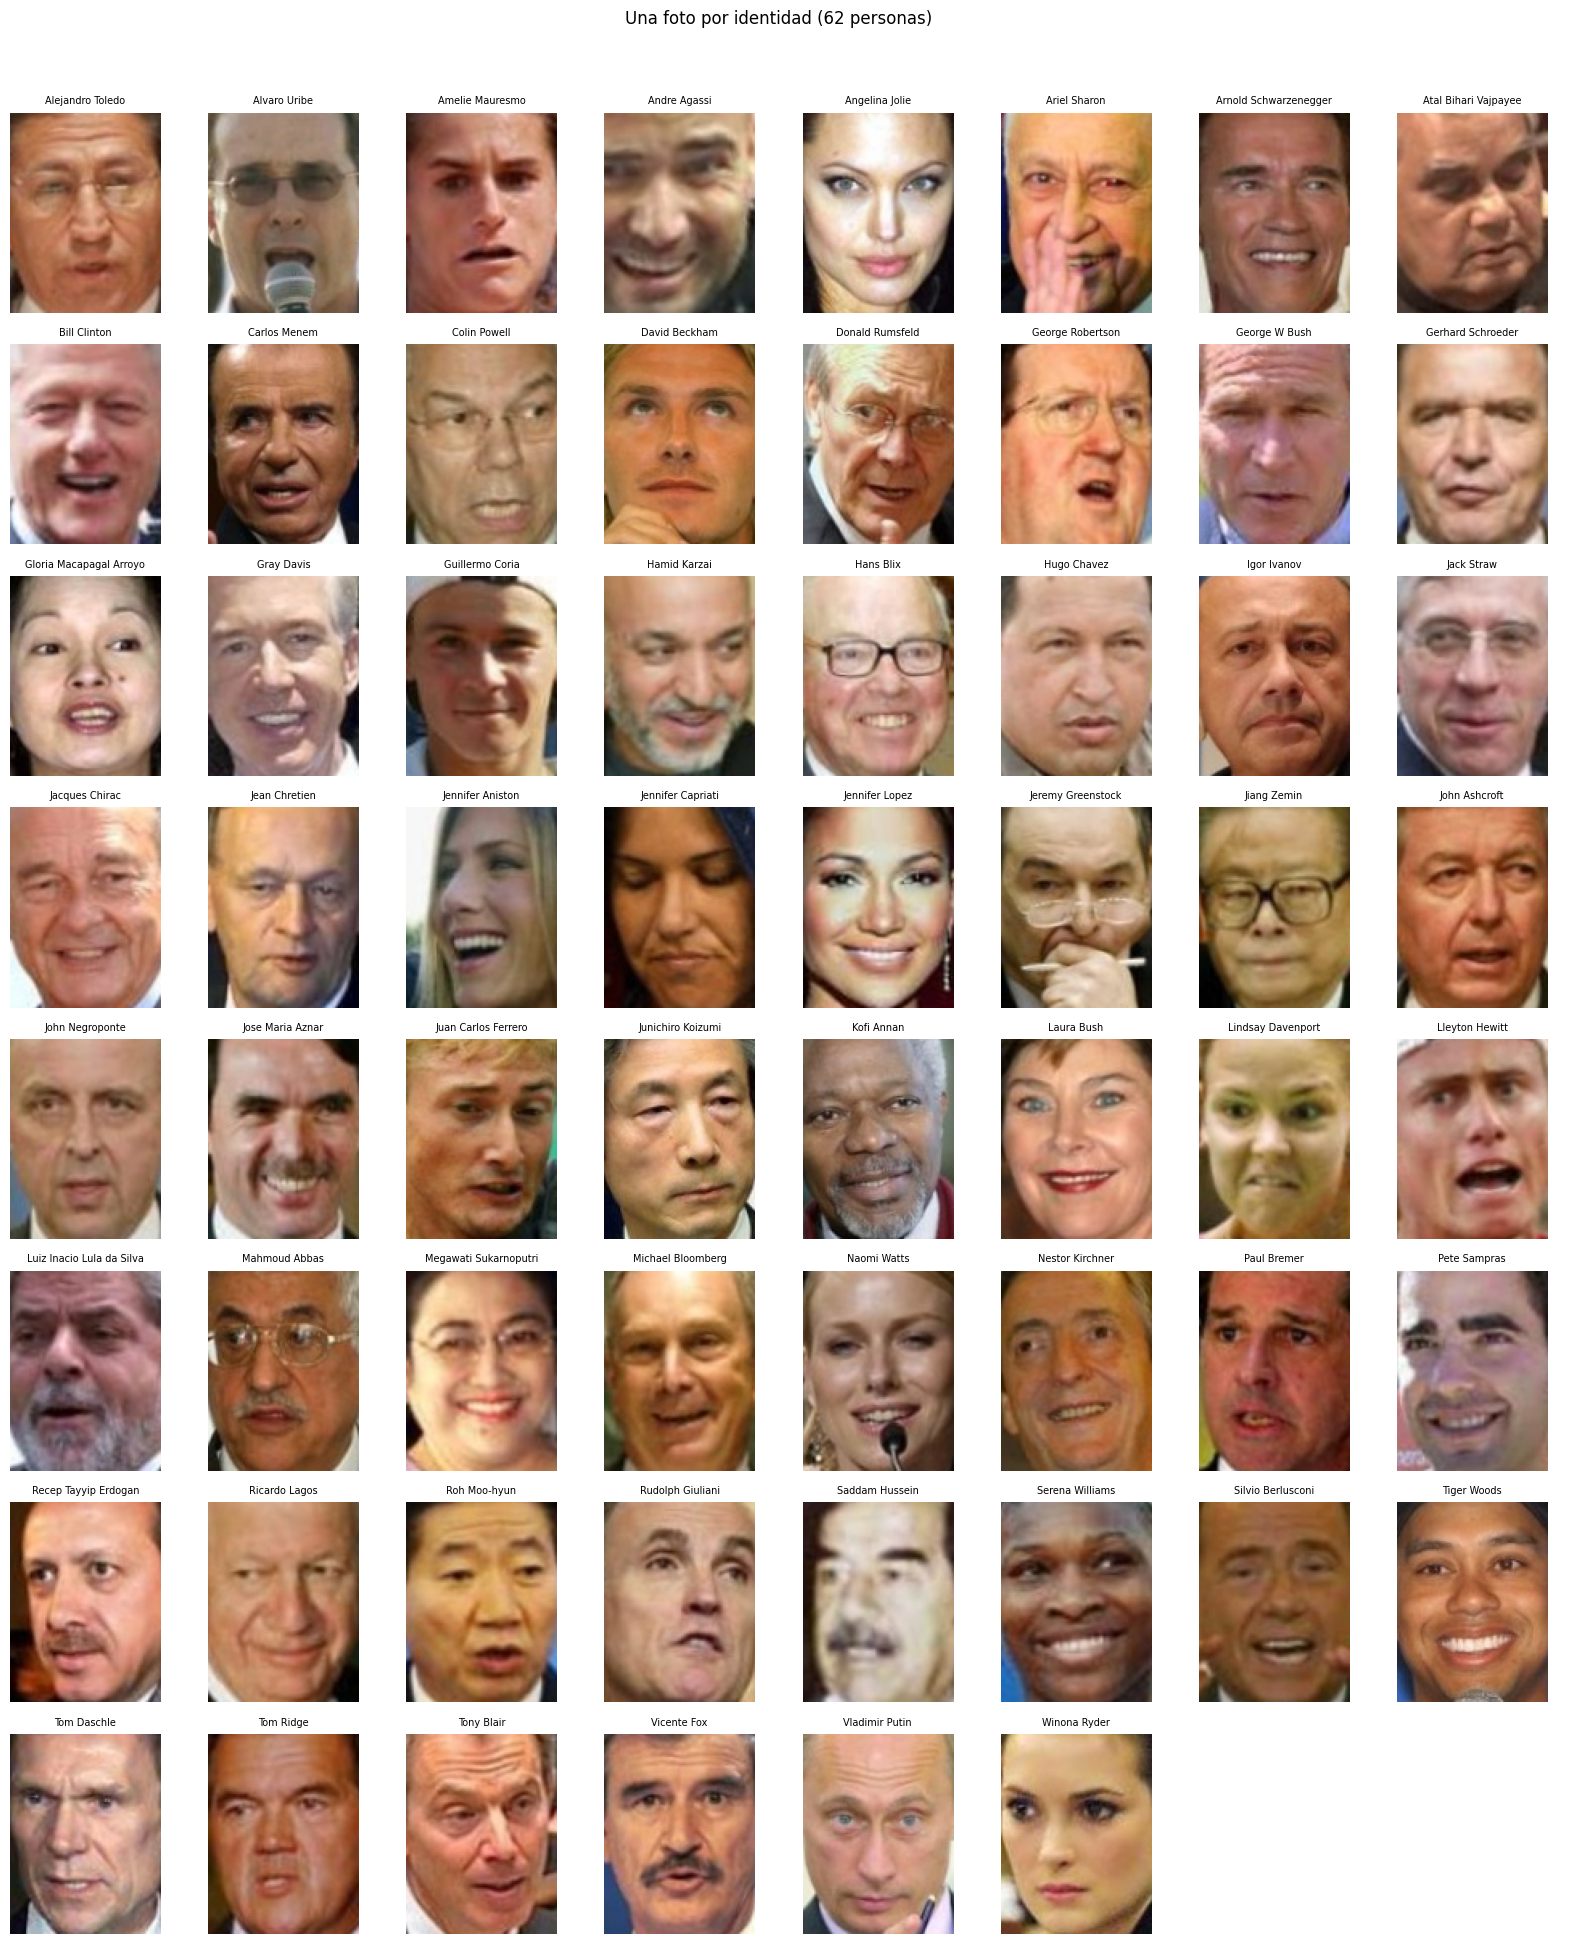

In [30]:
n = len(lfw.target_names)
cols = 8
filas = int(np.ceil(n / cols))

fig, axes = plt.subplots(filas, cols, figsize=(16, 2.4 * filas))
for ax in axes.flatten():
    ax.axis("off")

for pid in range(n):
    idx = np.where(lfw.target == pid)[0][0]
    ax = axes.flatten()[pid]
    ax.imshow(lfw.images[idx])
    ax.set_title(lfw.target_names[pid], fontsize=7)

plt.suptitle("Una foto por identidad (62 personas)", y=1.01)
plt.tight_layout(rect=[0, 0, 1, 0.99])
plt.show()

**Observaciones:** la grilla muestra una foto de cada una de las 62 identidades. Se aprecia que, aunque hay mujeres (por ejemplo Angelina Jolie, Jennifer Aniston o Lindsay Davenport), predominan los hombres y, en su mayoría, figuras políticas y públicas. También predominan las personas de piel clara, con pocas excepciones, lo que confirma la limitación de diversidad demográfica del dataset.

Se observa variación de expresión (muchas fotos con la boca abierta, hablando o con gestos marcados), de pose (caras giradas, inclinadas o mirando hacia abajo) y de oclusiones: anteojos, un micrófono frente a la cara (Álvaro Uribe) y manos u objetos que tapan parte del rostro (Ariel Sharon, Jeremy Greenstock). El encuadre también varía: algunas caras ocupan toda la imagen y otras muestran más fondo.

### Detección de rostros
Aplicamos el detector SCRFD de InsightFace (`buffalo_l`) a las 3.023 imágenes para (1) medir el tamaño del rostro dentro de la imagen y (2) aplicar la primera regla de calidad (imágenes sin cara o con más de una cara). Reutilizaremos este mismo detector en la alineación.

**Detector elegido: SCRFD.** Lo elegimos porque (1) es el mismo detector que usa la aplicación (`det_10g.onnx`), lo que garantiza que la notebook y la app procesen las imágenes de forma idéntica, (2) entrega, además de la caja, los 5 landmarks faciales necesarios para la alineación, y (3) ofrece un buen equilibrio entre precisión y velocidad. Sus pesos preentrenados son de uso no comercial / de investigación.

In [47]:
# Detector de InsightFace (SCRFD), solo detección
detector = FaceAnalysis(name="buffalo_l", allowed_modules=["detection"],
                        providers=["CPUExecutionProvider"])
detector.prepare(ctx_id=-1, det_size=(320, 320))

def a_bgr(img01, pad=40):
    """RGB [0,1] -> BGR uint8 (lo que espera InsightFace), con borde extra."""
    img = (img01 * 255).astype(np.uint8)[:, :, ::-1]
    img = np.ascontiguousarray(img)
    return cv2.copyMakeBorder(img, pad, pad, pad, pad, cv2.BORDER_REPLICATE)


In [48]:
t0 = time.time()

filas = []
for i in range(len(lfw.images)):
    caras = detector.get(a_bgr(lfw.images[i]))
    if caras:
        # si hay más de una cara, nos quedamos con la más grande
        c = max(caras, key=lambda c: (c.bbox[2] - c.bbox[0]) * (c.bbox[3] - c.bbox[1]))
        ancho, alto, score = c.bbox[2] - c.bbox[0], c.bbox[3] - c.bbox[1], float(c.det_score)
    else:
        ancho = alto = score = np.nan
    filas.append({"idx": i, "persona": lfw.target_names[lfw.target[i]],
                  "n_caras": len(caras), "ancho": ancho, "alto": alto, "score": score})

df_det = pd.DataFrame(filas)
df_det.to_csv("detecciones.csv", index=False)   # por si se reinicia la sesión

print(f"Tiempo: {time.time() - t0:.0f} s")
print(df_det["n_caras"].value_counts())

Tiempo: 259 s
n_caras
1    3000
0      23
Name: count, dtype: int64


### Tamaño del rostro dentro de la imagen
Para medir el tamaño de la cara usamos las cajas que devolvió el detector sobre las 3.023 imágenes. Medimos el ancho y el alto de la caja y qué porcentaje del área de la imagen ocupa, en las imágenes donde se detectó exactamente una cara. Esto nos dice qué tan "recortado" viene el dataset y cuánto hay que agrandar la cara para llegar al `FACE_SIZE` objetivo (112×112).

Imágenes con 1 cara: 3000 de 3023
Ancho de la cara (px): mediana 91 | mín 66 | máx 164
Alto de la cara (px):  mediana 125 | mín 83 | máx 234
La cara ocupa en mediana el 96% de la imagen (mín 51% | máx 327%)
Caras con ancho menor a 40 px: 0
Caras más chicas que FACE_SIZE (112 px de ancho): 2979 de 3000


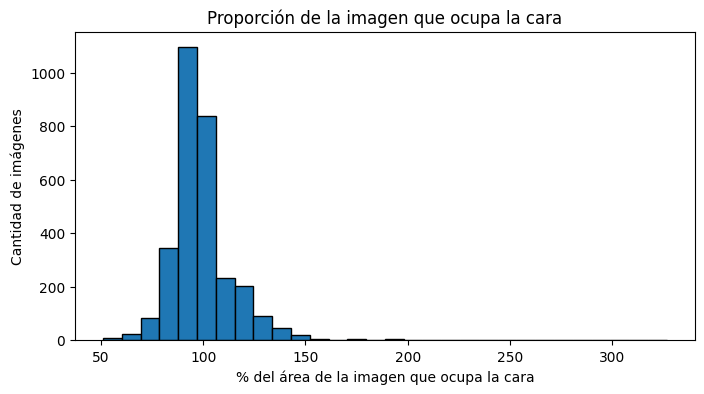

In [50]:
ok = df_det[df_det["n_caras"] == 1]
rel = ok["ancho"] * ok["alto"] / (125 * 94) * 100   # % del área de la imagen

print(f"Imágenes con 1 cara: {len(ok)} de {len(df_det)}")
print(f"Ancho de la cara (px): mediana {ok['ancho'].median():.0f} | mín {ok['ancho'].min():.0f} | máx {ok['ancho'].max():.0f}")
print(f"Alto de la cara (px):  mediana {ok['alto'].median():.0f} | mín {ok['alto'].min():.0f} | máx {ok['alto'].max():.0f}")
print(f"La cara ocupa en mediana el {rel.median():.0f}% de la imagen (mín {rel.min():.0f}% | máx {rel.max():.0f}%)")
print(f"Caras con ancho menor a 40 px: {(ok['ancho'] < 40).sum()}")
print(f"Caras más chicas que FACE_SIZE (112 px de ancho): {(ok['ancho'] < 112).sum()} de {len(ok)}")

plt.figure(figsize=(8, 4))
plt.hist(rel, bins=30, edgecolor="black")
plt.xlabel("% del área de la imagen que ocupa la cara")
plt.ylabel("Cantidad de imágenes")
plt.title("Proporción de la imagen que ocupa la cara")
plt.show()

El ancho mediano de la cara es de 91 px (rango 66 a 164 px) y el alto mediano de 125 px (rango 83 a 234 px). La cara ocupa en mediana el 96% del área de la imagen, con una distribución concentrada alrededor del 100% y una cola hacia la derecha de pocos casos (hasta 327%). Hay valores superiores a 100% porque la caja del detector incluye frente y mentón y se extiende más allá del borde de la imagen original. Ninguna cara mide menos de 40 px de ancho, por lo que esa regla de calidad no descarta imágenes.

**Conclusión:** las imágenes de LFW están recortadas casi exclusivamente alrededor del rostro, por lo que la cara ocupa prácticamente todo el cuadro. Esto es muy distinto de lo que recibirá la app (fotos completas, con fondo y a veces con varias personas), así que el rendimiento medido con este dataset podría ser optimista en la etapa de detección. Además, 2.979 de las 3.000 caras detectadas (99,3%) miden menos que el `FACE_SIZE` objetivo (112 px de ancho), por lo que casi todas deben agrandarse antes de pasarlas al modelo, con la consecuente pérdida de nitidez.

### Regla 1: imágenes sin cara detectada o con más de una cara
De las 3.023 imágenes, el detector encontró exactamente una cara en 3.000, ninguna en 23 y más de una en 0. Se descartan las 23 imágenes sin cara (0,8% del total), porque sin detección no se pueden obtener los landmarks necesarios para la alineación y la app exige exactamente una cara para registrar una identidad. Las caras no detectadas corresponden mayormente a poses muy giradas o de perfil, expresiones extremas y recortes muy ajustados.

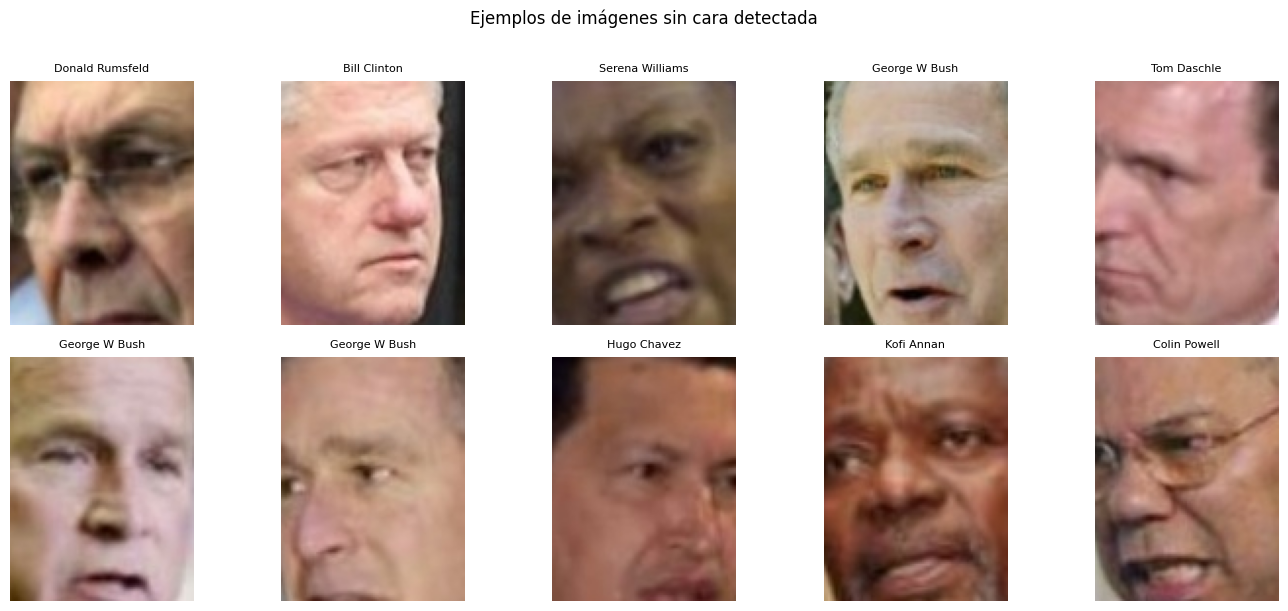

Descartadas por persona:
 persona
Colin Powell       4
Kofi Annan         4
George W Bush      3
Serena Williams    2
Bill Clinton       1
Donald Rumsfeld    1
Hugo Chavez        1
Tom Daschle        1
Hamid Karzai       1
Lleyton Hewitt     1
Name: count, dtype: int64

% de fotos descartadas por persona:
 persona
Kofi Annan          12.5
George Robertson     4.5
Hamid Karzai         4.5
Tiger Woods          4.3
Tom Daschle          4.0
Serena Williams      3.8
Ricardo Lagos        3.7
Bill Clinton         3.4
David Beckham        3.2
Lleyton Hewitt       2.4
Name: count, dtype: float64


In [51]:
# Ejemplos de imágenes sin cara detectada
idx_sin_cara = df_det[df_det["n_caras"] == 0]["idx"].values[:10]
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax in axes.flatten():
    ax.axis("off")
for ax, i in zip(axes.flatten(), idx_sin_cara):
    ax.imshow(lfw.images[i])
    ax.set_title(lfw.target_names[lfw.target[i]], fontsize=8)
plt.suptitle("Ejemplos de imágenes sin cara detectada", y=1.01)
plt.tight_layout()
plt.show()

# ¿A quiénes afecta?
sin_cara = df_det[df_det["n_caras"] == 0]
print("Descartadas por persona:\n", sin_cara["persona"].value_counts().head(10))

afectadas = (sin_cara["persona"].value_counts() / df_det["persona"].value_counts() * 100).dropna()
print("\n% de fotos descartadas por persona:\n", afectadas.sort_values(ascending=False).round(1).head(10))

**Efecto por identidad:** el descarte no es uniforme. Kofi Annan pierde el 12,5% de sus fotos (4 de 32), muy por encima del promedio (0,8%), y también se ven afectadas, en menor medida, Serena Williams (3,8%), Tiger Woods (4,3%) y Hamid Karzai (4,5%), entre otros. Aunque son pocos casos y la conclusión no es firme, es posible que el detector rinda peor con ciertas identidades o tonos de piel, lo que podría agravar el sesgo del dataset.